Clase 015 · `015_OurWorldData` · Un conjunto de datos público y grande: el *Energy dataset*
de Our World in Data, 23 377 filas (una por país y año) y 130 columnas. Exploración antes de
graficar: columnas, países, qué filas son agregados y no países, filtros con `isin`, y la
primera figura con `seaborn.relplot`, con `hue`, `size` y `col` para separar países. `seaborn`
se instala con `uv add seaborn`.

::: {.callout-important title="Datos"}
`owid-energy-data.csv` no viaja en el repositorio; descárgalo del repositorio
[`owid/energy-data`](https://github.com/owid/energy-data) de GitHub y colócalo en
`clases/015_OurWorldData/data/001_raw/`.
:::

## Librerías

`pandas`, `numpy` y `seaborn` con su alias `sns`. seaborn dibuja sobre matplotlib, así que no
hace falta importarlo en esta libreta.

In [42]:
import pandas as pd
import numpy as np
import seaborn as sns

## Leer el archivo

Sin `index_col` ni `parse_dates`: no es una serie temporal con la fecha como índice, sino una
tabla con una fila por país y año. `head(2)` ya muestra que la primera entidad es
`ASEAN (Ember)`, un agregado regional y no un país, y que muchas columnas vienen en `NaN`.

In [3]:
f = "../data/001_raw/owid-energy-data.csv"
owid = pd.read_csv(f)
owid.head(2)

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


## `info()`

23 377 filas y 130 columnas: 127 flotantes, una entera (`year`) y dos de texto (`country`,
`iso_code`). Con tantas columnas `info()` ya no las lista una por una.

In [4]:
owid.info()

<class 'pandas.DataFrame'>
RangeIndex: 23377 entries, 0 to 23376
Columns: 130 entries, country to wind_share_energy
dtypes: float64(127), int64(1), str(2)
memory usage: 23.2 MB


## Las columnas, una por línea

Un ciclo sobre `owid.columns` imprime los 130 nombres. Siguen un patrón, `fuente_medida`:
`coal_consumption`, `solar_share_elec`, `wind_elec_per_capita`… Leer la lista completa una vez
es la forma de saber qué preguntas se le pueden hacer al archivo.

In [6]:
for column in owid.columns:
    print(column)

country
year
iso_code
population
gdp
biofuel_cons_change_pct
biofuel_cons_change_twh
biofuel_cons_per_capita
biofuel_consumption
biofuel_elec_per_capita
biofuel_electricity
biofuel_share_elec
biofuel_share_energy
carbon_intensity_elec
coal_cons_change_pct
coal_cons_change_twh
coal_cons_per_capita
coal_consumption
coal_elec_per_capita
coal_electricity
coal_prod_change_pct
coal_prod_change_twh
coal_prod_per_capita
coal_production
coal_share_elec
coal_share_energy
electricity_demand
electricity_demand_per_capita
electricity_generation
electricity_share_energy
energy_cons_change_pct
energy_cons_change_twh
energy_per_capita
energy_per_gdp
fossil_cons_change_pct
fossil_cons_change_twh
fossil_elec_per_capita
fossil_electricity
fossil_energy_per_capita
fossil_fuel_consumption
fossil_share_elec
fossil_share_energy
gas_cons_change_pct
gas_cons_change_twh
gas_consumption
gas_elec_per_capita
gas_electricity
gas_energy_per_capita
gas_prod_change_pct
gas_prod_change_twh
gas_prod_per_capita
gas_produ

## Los países

`country.unique()` da los valores distintos de la columna. Entre los países aparecen regiones y
agregados con la fuente entre paréntesis: `Africa (EI)`, `Asia (Ember)`, `World`.

In [10]:
for country in owid.country.unique():
    print(country)

ASEAN (Ember)
Afghanistan
Africa
Africa (EI)
Africa (EIA)
Africa (Ember)
Africa (Shift)
Albania
Algeria
American Samoa
Angola
Antarctica
Antigua and Barbuda
Argentina
Armenia
Aruba
Asia
Asia (Ember)
Asia Pacific (EI)
Asia and Oceania (EIA)
Asia and Oceania (Shift)
Australia
Australia and New Zealand (EIA)
Austria
Azerbaijan
Bahamas
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bermuda
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
British Virgin Islands
Brunei
Bulgaria
Burkina Faso
Burundi
CIS (EI)
Cambodia
Cameroon
Canada
Cape Verde
Cayman Islands
Central African Republic
Central America (EI)
Central and South America (EIA)
Central and South America (Shift)
Chad
Chile
China
Colombia
Comoros
Congo
Cook Islands
Costa Rica
Cote d'Ivoire
Croatia
Cuba
Curacao
Cyprus
Czechia
Czechoslovakia
Democratic Republic of Congo
Denmark
Djibouti
Dominica
Dominican Republic
EU (Ember)
EU28 (Shift)
East Germany
East Timor
Eastern Africa (EI)
Eastern Europe and Eurasia (EIA)
Ecuador
Egy

`iso_code` tiene 221 valores distintos y el primero es `nan`: hay filas sin código ISO.

In [11]:
owid.iso_code.unique()

<StringArray>
[  nan, 'AFG', 'ALB', 'DZA', 'ASM', 'AGO', 'ATA', 'ATG', 'ARG', 'ARM',
 ...
 'VIR', 'URY', 'UZB', 'VUT', 'VEN', 'VNM', 'ESH', 'YEM', 'ZMB', 'ZWE']
Length: 221, dtype: str

`head(4)` para volver a mirar la tabla con eso en mente: las filas de `ASEAN (Ember)` no tienen `iso_code`.

In [18]:
owid.head(4)

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


## Qué filas no son países

Filtro booleano con `isna()`: las entidades sin código ISO son justamente los agregados
(continentes, regiones, `World`, grupos de ingreso). Son 94. Es el criterio para separar países
de regiones en este archivo.

In [27]:
owid[owid.iso_code.isna()].country.unique()

<StringArray>
[                        'ASEAN (Ember)',
                                'Africa',
                           'Africa (EI)',
                          'Africa (EIA)',
                        'Africa (Ember)',
                        'Africa (Shift)',
                                  'Asia',
                          'Asia (Ember)',
                     'Asia Pacific (EI)',
                'Asia and Oceania (EIA)',
              'Asia and Oceania (Shift)',
       'Australia and New Zealand (EIA)',
                              'CIS (EI)',
                  'Central America (EI)',
       'Central and South America (EIA)',
     'Central and South America (Shift)',
                        'Czechoslovakia',
                            'EU (Ember)',
                          'EU28 (Shift)',
                          'East Germany',
                   'Eastern Africa (EI)',
      'Eastern Europe and Eurasia (EIA)',
                         'Eurasia (EIA)',
                    

Guardamos la lista completa de entidades en `paises`: 314, países y agregados juntos.

In [28]:
paises = owid.country.unique()
paises

<StringArray>
[       'ASEAN (Ember)',          'Afghanistan',               'Africa',
          'Africa (EI)',         'Africa (EIA)',       'Africa (Ember)',
       'Africa (Shift)',              'Albania',              'Algeria',
       'American Samoa',
 ...
  'Wake Island (Shift)',         'West Germany',  'Western Africa (EI)',
 'Western Europe (EIA)',       'Western Sahara',                'World',
                'Yemen',           'Yugoslavia',               'Zambia',
             'Zimbabwe']
Length: 314, dtype: str

## Filtrar varios países con `isin`

`isin` recibe una lista y devuelve `True` en las filas cuyo `country` está en ella. Con México,
Zambia y Estados Unidos quedan 377 filas. Se reutiliza el nombre `paises`, que ahora es un
DataFrame y no una lista de nombres.

In [41]:
lista_paises = ["Mexico","Zambia","United States"]
paises = owid[owid.country.isin(lista_paises)]
paises

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
12323,Mexico,1900,MEX,13261087.0,2.479195e+10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12324,Mexico,1901,MEX,13411660.0,2.691854e+10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12325,Mexico,1902,MEX,13550290.0,2.497158e+10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12326,Mexico,1903,MEX,13676676.0,2.780079e+10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12327,Mexico,1904,MEX,13804239.0,2.830234e+10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23247,Zambia,2020,ZMB,19059394.0,6.328162e+10,NaN,0.0,0.0,0.0,4.197,...,0.985,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23248,Zambia,2021,ZMB,19603610.0,6.619194e+10,NaN,0.0,0.0,0.0,4.081,...,0.847,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23249,Zambia,2022,ZMB,20152935.0,6.846960e+10,NaN,0.0,0.0,0.0,3.970,...,0.719,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23250,Zambia,2023,ZMB,20723967.0,NaN,NaN,0.0,0.0,0.0,3.860,...,0.771,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN


El mismo tipo de filtro con una comparación simple, por código ISO: Estados Unidos tiene 126
filas, de 1900 a 2025.

In [39]:
owid[owid.iso_code=="USA"]

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
21873,United States,1900,USA,74829905.0,6.139981e+11,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21874,United States,1901,USA,76245912.0,6.831061e+11,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21875,United States,1902,USA,77698268.0,6.901269e+11,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21876,United States,1903,USA,79187838.0,7.237663e+11,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21877,United States,1904,USA,80705948.0,7.146218e+11,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21994,United States,2021,USA,340161438.0,1.909938e+13,9.917,37.518,1222.477,415.839,159.483,...,3.958,1.585,11.913,98.085,940.928,1111.825,378.20,2766.123,9.105,3.647
21995,United States,2022,USA,341534041.0,1.949317e+13,5.231,21.754,1281.259,437.593,151.815,...,4.784,1.932,14.834,136.920,1077.848,1271.615,434.30,3155.903,10.131,4.091
21996,United States,2023,USA,343477330.0,NaN,13.148,57.535,1441.518,495.129,137.418,...,5.617,2.261,-3.029,-40.299,1037.550,1226.107,421.14,3020.722,9.900,3.985
21997,United States,2024,USA,345426566.0,NaN,5.759,28.514,1515.929,523.642,134.385,...,6.918,2.835,7.673,79.608,1117.157,1308.238,451.90,3234.138,10.291,4.240


Los códigos ISO uno por línea, para buscar uno rápido con la vista.

In [36]:
for pais in owid.iso_code.unique():
    print(pais)

nan
AFG
ALB
DZA
ASM
AGO
ATA
ATG
ARG
ARM
ABW
AUS
AUT
AZE
BHS
BHR
BGD
BRB
BLR
BEL
BLZ
BEN
BMU
BTN
BOL
BIH
BWA
BRA
VGB
BRN
BGR
BFA
BDI
KHM
CMR
CAN
CPV
CYM
CAF
TCD
CHL
CHN
COL
COM
COG
COK
CRI
CIV
HRV
CUB
CUW
CYP
CZE
COD
DNK
DJI
DMA
DOM
TLS
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FLK
FRO
FJI
FIN
FRA
GUF
PYF
GAB
GMB
GEO
DEU
GHA
GIB
GRC
GRL
GRD
GLP
GUM
GTM
GIN
GNB
GUY
HTI
HND
HKG
HUN
ISL
IND
IDN
IRN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KIR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LBY
LTU
LUX
MAC
MDG
MWI
MYS
MDV
MLI
MLT
MTQ
MRT
MUS
MEX
FSM
MDA
MNG
MNE
MSR
MAR
MOZ
MMR
NAM
NRU
NPL
NLD
ANT
NCL
NZL
NIC
NER
NGA
NIU
PRK
MKD
MNP
NOR
OMN
PAK
PSE
PAN
PNG
PRY
PER
PHL
POL
PRT
PRI
QAT
REU
ROU
RUS
RWA
SHN
KNA
LCA
SPM
VCT
WSM
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
SLB
SOM
ZAF
KOR
SSD
ESP
LKA
SDN
SUR
SWE
CHE
SYR
TWN
TJK
TZA
THA
TGO
TON
TTO
TUN
TUR
TKM
TCA
TUV
UGA
UKR
ARE
GBR
USA
VIR
URY
UZB
VUT
VEN
VNM
ESH
YEM
ZMB
ZWE


`paises.columns` muestra las 130 columnas resumidas, con `...` en medio.

In [43]:
paises.columns

Index(['country', 'year', 'iso_code', 'population', 'gdp',
       'biofuel_cons_change_pct', 'biofuel_cons_change_twh',
       'biofuel_cons_per_capita', 'biofuel_consumption',
       'biofuel_elec_per_capita',
       ...
       'solar_share_elec', 'solar_share_energy', 'wind_cons_change_pct',
       'wind_cons_change_twh', 'wind_consumption', 'wind_elec_per_capita',
       'wind_electricity', 'wind_energy_per_capita', 'wind_share_elec',
       'wind_share_energy'],
      dtype='str', length=130)

## Primera figura con `seaborn.relplot`

`relplot` dibuja relaciones entre dos variables; recibe el DataFrame en `data` y los nombres de
las columnas en `x` y `y`. `hue="country"` colorea por país y agrega la leyenda. Las líneas
comentadas en `lista_paises` dejan sólo a México. La población pasa de unos 13 millones en 1900
a 130 en 2025, con el quiebre de crecimiento después de 1940.

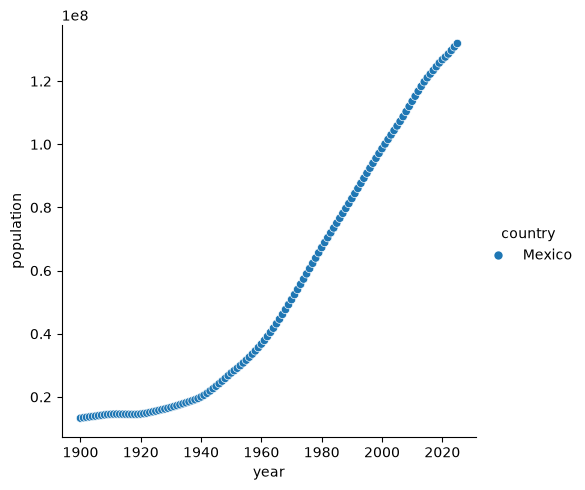

In [47]:
#| label: fig-owid-poblacion-mexico
#| fig-cap: "Población de México de 1900 a 2025 según Our World in Data, con `seaborn.relplot`. El crecimiento se acelera a partir de los años cuarenta."
#| fig-alt: "Puntos azules que suben de 13 millones a 130 millones; casi planos hasta 1940 y después en una recta ascendente."
lista_paises = [
    "Mexico",
    # "Zambia",
    # "United States"
]
paises = owid[owid.country.isin(lista_paises)]

sns.relplot(
    data=paises,
    x="year",
    y="population",
    hue="country"
)

`paises.columns` otra vez, buscando qué otra variable graficar.

In [49]:
paises.columns

Index(['country', 'year', 'iso_code', 'population', 'gdp',
       'biofuel_cons_change_pct', 'biofuel_cons_change_twh',
       'biofuel_cons_per_capita', 'biofuel_consumption',
       'biofuel_elec_per_capita',
       ...
       'solar_share_elec', 'solar_share_energy', 'wind_cons_change_pct',
       'wind_cons_change_twh', 'wind_consumption', 'wind_elec_per_capita',
       'wind_electricity', 'wind_energy_per_capita', 'wind_share_elec',
       'wind_share_energy'],
      dtype='str', length=130)

Y la lista completa de columnas, una por línea, para elegir.

In [56]:
for columna in owid.columns:
    print(columna)

country
year
iso_code
population
gdp
biofuel_cons_change_pct
biofuel_cons_change_twh
biofuel_cons_per_capita
biofuel_consumption
biofuel_elec_per_capita
biofuel_electricity
biofuel_share_elec
biofuel_share_energy
carbon_intensity_elec
coal_cons_change_pct
coal_cons_change_twh
coal_cons_per_capita
coal_consumption
coal_elec_per_capita
coal_electricity
coal_prod_change_pct
coal_prod_change_twh
coal_prod_per_capita
coal_production
coal_share_elec
coal_share_energy
electricity_demand
electricity_demand_per_capita
electricity_generation
electricity_share_energy
energy_cons_change_pct
energy_cons_change_twh
energy_per_capita
energy_per_gdp
fossil_cons_change_pct
fossil_cons_change_twh
fossil_elec_per_capita
fossil_electricity
fossil_energy_per_capita
fossil_fuel_consumption
fossil_share_elec
fossil_share_energy
gas_cons_change_pct
gas_cons_change_twh
gas_consumption
gas_elec_per_capita
gas_electricity
gas_energy_per_capita
gas_prod_change_pct
gas_prod_change_twh
gas_prod_per_capita
gas_produ

## Un panel por país con `col`

Los tres países de vuelta en la lista. `col="country"` hace un panel por país en vez de
superponerlos; `size="gdp"` escala el tamaño del punto con el PIB, lo que explica los puntos
grandes de Estados Unidos al final. `x=owid.year*1` es una curiosidad de la clase: en vez del
nombre de la columna se pasa la columna completa de `owid` multiplicada por 1; seaborn la
alinea con `paises` por el índice y funciona, aunque `x="year"` es lo claro. Los tres paneles
comparten el eje vertical, por eso Zambia se ve aplastada contra el cero.

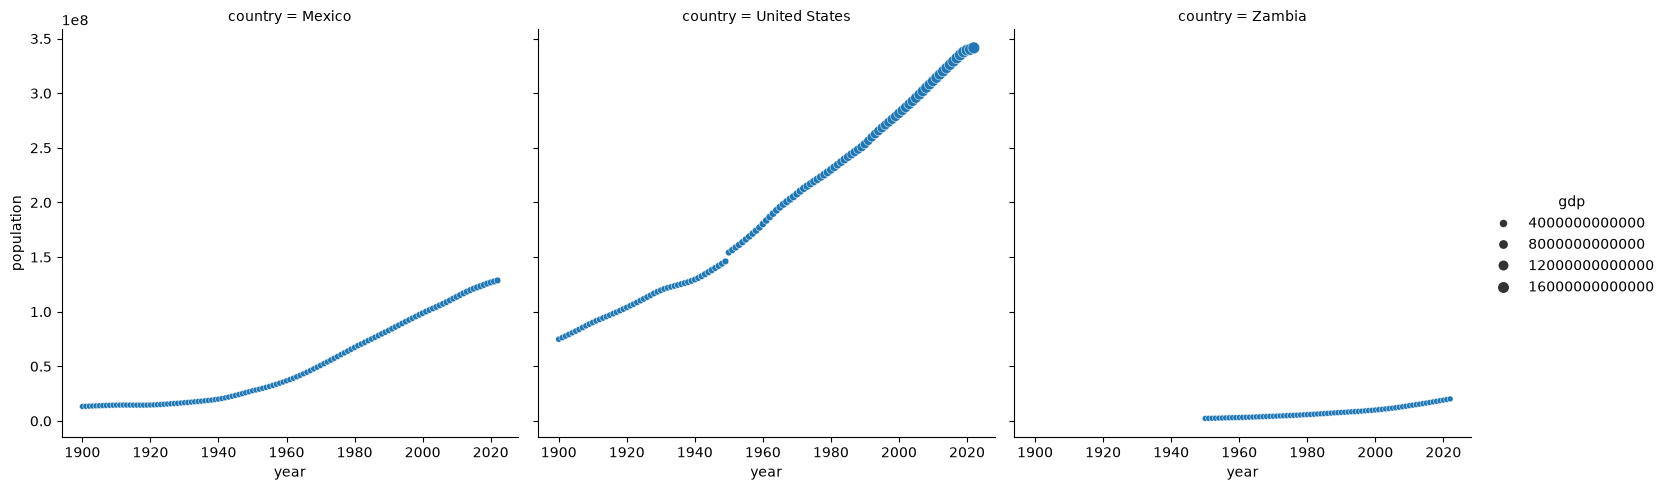

In [63]:
#| label: fig-owid-poblacion-tres-paises
#| fig-cap: "Población de México, Estados Unidos y Zambia de 1900 a 2025, un panel por país con `col=\"country\"`; el tamaño del punto es el PIB. Con el eje vertical compartido, Zambia queda aplastada contra el cero."
#| fig-alt: "Tres paneles con puntos azules; Estados Unidos llega a 340 millones con puntos grandes al final, México a 130 millones y Zambia apenas se despega del eje desde 1950."
lista_paises = [
    "Mexico",
    "Zambia",
    "United States"
]
paises = owid[owid.country.isin(lista_paises)]

sns.relplot(
    data=paises,
    x=owid.year*1,
    y="population",
    # hue="country",
    size="gdp",
    # aspect=3.5,
    col="country"
)